In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from regresi import (
    prepare_data, train_and_evaluate, plot_actual_vs_pred,
    plot_heatmap, plot_linearitas, plot_engagement, predict_likes,
)

# Dataset utama hasil crawling
df = pd.read_csv('Timnas_Indonesia/dataset_timnas.csv')
df.head()

,text_raw,text,created_at,like_count
0,"@googlemoody padahal, banner tersebut menjelas...",padahal banner tersebut menjelaskan tentang ke...,2026-10-08T18:30:01.000Z,0
1,@googlemoody yang rame-rame saat ini setelah t...,yang rame rame saat ini setelah timnas indones...,2026-10-08T18:24:41.000Z,1
2,TC Piala Asia 2027 Dimulai Kapan? Ini Rencana ...,tc piala asia 2027 dimulai kapan ini rencana j...,2026-10-08T18:01:26.000Z,0
3,Calvin Verdonk Ditunggu Arsenal Usai Antar Tim...,calvin verdonk ditunggu arsenal usai antar tim...,2026-10-08T17:48:27.000Z,0
4,@IjoelSi @FaktaSepakbola Tapi bagi pemain Timn...,tapi bagi pemain timnas indonesia 10 000 itu d...,2026-10-08T17:34:38.000Z,0


## Distribusi Likes (alasan memakai log)

Likes sangat miring ke kanan: sebagian besar postingan 0 likes, sedikit sekali yang viral.
Regresi linear sensitif pada nilai ekstrem seperti ini, sehingga garis tidak mewakili data.

Persentase postingan 0 likes: 66.2 %
count     284.000000
mean       35.309859
std       221.730208
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max      3173.000000
Name: like_count, dtype: float64


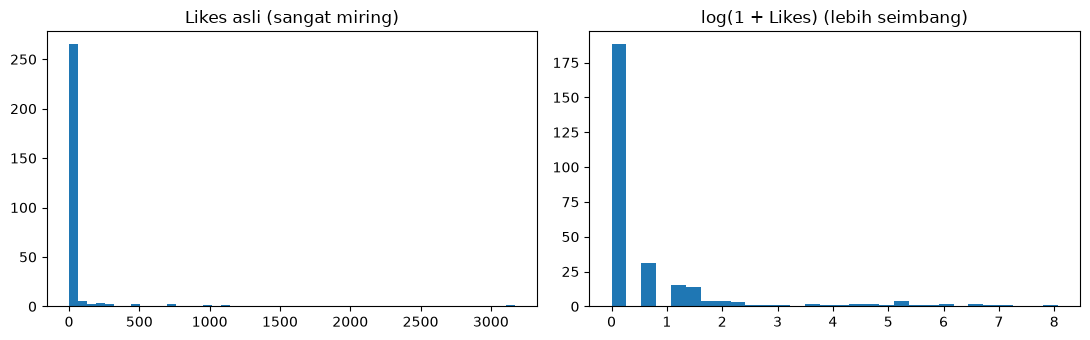

In [2]:
df_raw = prepare_data(df)
print("Persentase postingan 0 likes:", round((df_raw['like_count'] == 0).mean() * 100, 1), "%")
print(df_raw['like_count'].describe())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(df_raw['like_count'], bins=50)
ax[0].set_title('Likes asli (sangat miring)')
ax[1].hist(df_raw['log_like'], bins=30)
ax[1].set_title('log(1 + Likes) (lebih seimbang)')
plt.tight_layout()
plt.show()

In [3]:
df_raw[['text', 'word_count', 'hashtag_count', 'like_count', 'log_like']].head()

,text,word_count,hashtag_count,like_count,log_like
0,padahal banner tersebut menjelaskan tentang ke...,33,0,0,0.000000
1,yang rame rame saat ini setelah timnas indones...,39,0,1,0.693147
2,tc piala asia 2027 dimulai kapan ini rencana j...,13,0,0,0.000000
3,calvin verdonk ditunggu arsenal usai antar tim...,15,0,0,0.000000
4,tapi bagi pemain timnas indonesia 10 000 itu d...,10,0,0,0.000000


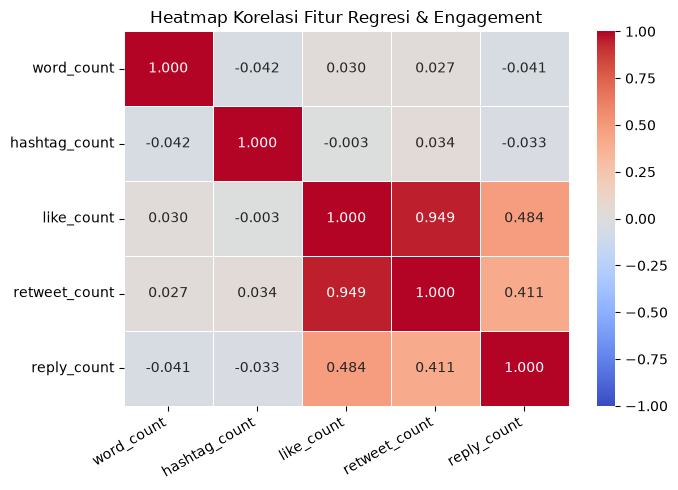

In [4]:
fig = plot_heatmap(df)
plt.show()

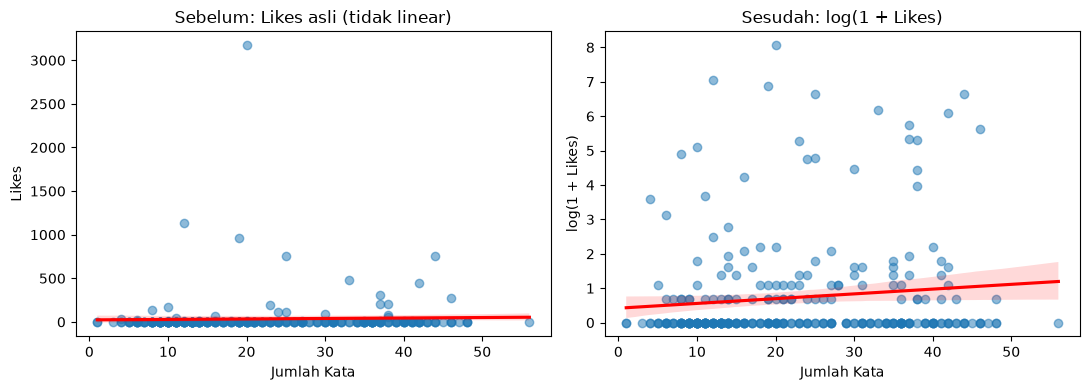

In [5]:
fig = plot_linearitas(df)
plt.show()

## Latih dan evaluasi model

* **R²** dihitung pada skala log (skala saat model dilatih).
* **MAE** dikembalikan ke skala likes asli agar mudah dibaca.

In [6]:
model, mae, r2, y_test, y_pred = train_and_evaluate(df)
print(f"MAE (skala likes asli): {mae:.2f}")
print(f"R2 Score (skala log)  : {r2:.4f}")
print("Koefisien word_count, hashtag_count:", model.coef_)

MAE (skala likes asli): 2.42
R2 Score (skala log)  : -0.4081
Koefisien word_count, hashtag_count: [0.01570431 0.13012311]


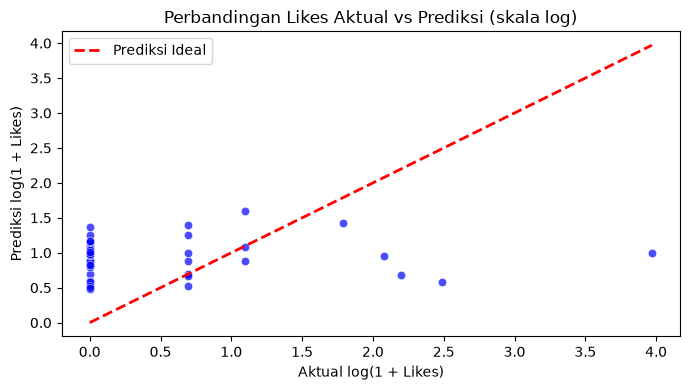

In [7]:
fig = plot_actual_vs_pred(y_test, y_pred)
plt.show()

## Analisis tambahan: retweet vs likes

Ini korelasi antar-engagement, **bukan** model prediksi.

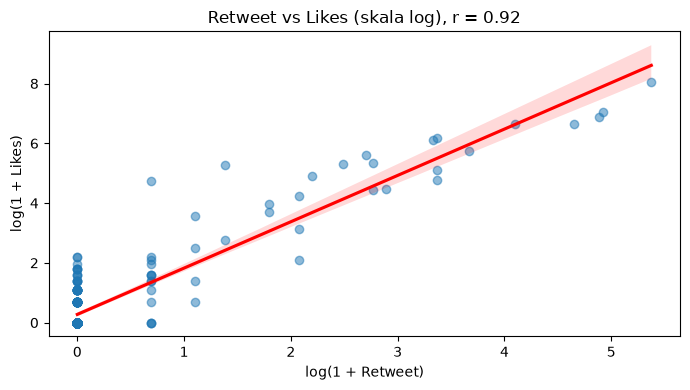

In [8]:
fig = plot_engagement(df)
if fig is not None:
    plt.show()

In [9]:
print(f"12 kata, 2 hashtag -> {predict_likes(model, 12, 2):.1f} likes")

12 kata, 2 hashtag -> 1.3 likes


## Kesimpulan

* Transformasi log membuat distribusi likes lebih seimbang dan model lebih stabil terhadap outlier.
* Korelasi `word_count` dan `hashtag_count` terhadap likes sangat lemah. R² mendekati 0 atau negatif.
* Jumlah kata dan hashtag belum cukup untuk memperkirakan likes. Faktor lain (jangkauan akun, media, waktu unggah) kemungkinan lebih berpengaruh.